# Genetic optimization of whistle geometry

This notebook walks through defining a seed design, running the opt-in geometry genetic algorithm, and examining the resulting bore, toneholes, and tuning. Run from the repository root with the project environment active.

One GA run varies all six hole positions, finger-opening diameters, chimney heights and bore-side conical bevel angles independently, plus the bore radii and endhole radius. Dimensional genes use 0.1 mm resolution; angles vary continuously within 0-15 degrees. Each bore radius can decrease by up to 20% from the previous one; the endhole can decrease by up to 30% from the last hole radius through a 20 mm terminal taper. Duplicate individuals are replaced with random candidates.

The configurable body exterior is at most 16 mm in diameter, with at least 0.9 mm wall/chimney height. Each hole height is at most outer diameter / 2 minus local bore radius. Local exterior radii may vary. OpenWInD conical holes use radius = finger radius + height * tan(bevel) at the bore, and radius_out = finger radius at the exterior. Inner openings are constrained to fit the bore; 5-8 mm refers to finger-opening diameter. This is a full-height cone, not a short chamfer.

Pipe length varies genetically but is not retuned during scoring. Root errors have 10 times the pitch weight of other notes, whose errors are relative to their register's actual root. Pitch cost combines normalized weighted register means at 60% lower / 40% upper. Combined cost subtracts a bounded reward for higher Q: weight * mean[Q/(Q+scale)], using equal notes within each 60/40 register. Defaults are weight=1 and scale=40; unavailable Q earns zero. Negative combined costs are valid. A fixed random seed makes the search reproducible for the same archive snapshot, not globally optimal.

## 1. Configure the search

`notes=None` scores eight lower-register targets, including the fork, and seven upper-register targets, including the vented root but no forks. Missing resonances receive a 1200-cent error; unresolved Q earns no reward. Search budget is configured below. Restart the kernel after changing optimizer code. Revision 4 archives distinguish the new genome, manufacturing constraints and reward settings from historical designs.

In [3]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from tin_whistle_openwind import GeneticAlgorithmConfig, WhistleDesignPipeline

GA_CONFIG = GeneticAlgorithmConfig(
    population_size=32,
    generations=10,
    elite_count=2,
    crossover_rate=0.8,
    mutation_rate=0.15,
    mutation_scale=0.08,
    bore_radius_variation_fraction=0.20,
    random_seed=42,
    retune_closed_root=False,
    root_relative_q=True,
    include_second_register=True,
    optimize_endhole=True,
    optimize_bevel=True,
    independent_hole_geometry=True,
    max_outer_diameter_m=16.0 / 1000,
    minimum_wall_m=0.9 / 1000,
    q_reward_weight=1.0,
    q_reward_scale=40.0,
)
NOTES = None
print(GA_CONFIG)

GeneticAlgorithmConfig(population_size=32, generations=10, elite_count=2, crossover_rate=0.8, mutation_rate=0.15, mutation_scale=0.08, bore_radius_variation_fraction=0.2, random_seed=42, retune_closed_root=False, include_second_register=True, optimize_endhole=True, optimize_bevel=True, independent_hole_geometry=True, max_outer_diameter_m=0.016, minimum_wall_m=0.0009, q_reward_weight=1.0, q_reward_scale=40.0, root_relative_q=True, workers=None, winner_directory=WindowsPath('C:/projects/p/openWind/data/ga-winners'))


## 2. Build the seed with the existing stages

Stage 1 estimates the pipe length/endhole and Stage 2 fits the toneholes. Start from the final Stage 2 bore. The GA-adapted seed is quantized and repaired: Stage 2's 3 mm chimneys may exceed the exterior envelope and be shortened. The initial GA score describes that adapted seed, not the unmodified Stage 2 geometry.

In [4]:
pipeline = WhistleDesignPipeline("Soprano_D", optimize_endhole=True, mouthpiece_name="MouthpieceDN16V4")
stage_1_bore = pipeline.run_stage_1_length_endhole_optimization(starting_bore_radius_m=14.2 / 2000.0)
stage_2_holes = pipeline.run_stage_2_tonehole_optimization(stage_1_bore)

seed_bore = pipeline.tonehole_result.bore
seed_layout = stage_2_holes
print(f"Seed pipe length: {seed_bore.length_m * 1000:.2f} mm")
print(f"Stage 2 tuning cost: {pipeline.tonehole_result.final_cost:.4f}")
print(f"Seed bore segments: {len(seed_bore.segments)}")
print(f"Seed toneholes: {len(seed_layout.holes)}")

Seed pipe length: 214.10 mm
Stage 2 tuning cost: 859.8515
Seed bore segments: 3
Seed toneholes: 6


## 3. Run genetic refinement

This step evaluates candidate designs through OpenWInD. Each candidate requires a sweep for each note, so the candidate count is not the number of acoustic sweeps.

In [8]:
from time import perf_counter

def report_generation(generation, best_cost, best_fitness, evaluations):
    print(
        f"Generation {generation:>2}/{GA_CONFIG.generations}: "
        f"best cost={best_cost:.6f}, fitness={best_fitness:.6f}, "
        f"unique candidates={evaluations}"
    )

started = perf_counter()
ga_result = pipeline.run_genetic_refinement(
    seed_bore,
    seed_layout,
    config=GA_CONFIG,
    notes=NOTES,
    progress_callback=report_generation,
)
elapsed_seconds = perf_counter() - started
print(f"Elapsed: {elapsed_seconds:.1f} s")
print(f"Unique GA candidates scored: {ga_result.evaluations}")
print(f"Pipe length: {seed_bore.length_m * 1000:.3f} -> {ga_result.bore.length_m * 1000:.3f} mm")
print(f"Endhole radius: {seed_bore.segments[-1][1] * 1000:.3f} -> {ga_result.bore.segments[-1][1] * 1000:.3f} mm")
print(f"Pitch cost: {ga_result.initial_pitch_cost:.8f} -> {ga_result.final_pitch_cost:.8f}")
print(f"Q reward: {ga_result.initial_q_reward:.8f} -> {ga_result.final_q_reward:.8f}")
print(f"Combined cost (pitch - Q reward): {ga_result.initial_cost:.8f} -> {ga_result.final_cost:.8f}")
print(f"Cost reduction: {ga_result.initial_cost - ga_result.final_cost:.8f}")
print(f"Fitness: {ga_result.initial_fitness:.8f} -> {ga_result.final_fitness:.8f}")
print(f"Improved combined cost: {ga_result.improved}")
print(f"Closed-root within 0.1 cent (diagnostic only): {ga_result.root_tuning_satisfied}")

Generation  1/10: best cost=469.106885, fitness=469.106885, unique candidates=32
Generation  2/10: best cost=451.291533, fitness=451.291533, unique candidates=62
Generation  3/10: best cost=446.864873, fitness=446.864873, unique candidates=92
Generation  4/10: best cost=446.864873, fitness=446.864873, unique candidates=121
Generation  5/10: best cost=446.864873, fitness=446.864873, unique candidates=151
Generation  6/10: best cost=432.019955, fitness=432.019955, unique candidates=181
Generation  7/10: best cost=431.051936, fitness=431.051936, unique candidates=211
Generation  8/10: best cost=409.140869, fitness=409.140869, unique candidates=241
Generation  9/10: best cost=409.140869, fitness=409.140869, unique candidates=270
Generation 10/10: best cost=409.140869, fitness=409.140869, unique candidates=299
Elapsed: 160.7 s
Unique GA candidates scored: 329
Pipe length: 214.100 -> 214.200 mm
Endhole radius: 7.100 -> 6.400 mm
Pitch cost: 733.23133860 -> 395.74793741
Q reward: 0.61716520 ->

## 4. Inspect the result

Pitch and Q tables compare the GA-adapted seed with the winner. Absolute errors show pitch against targets; scoring errors show non-root intervals relative to the measured root. Missing/unresolved Q is NaN and earns no reward. Exterior dimensions below exclude the fixed mouthpiece. Validate passive-model Q with dense sweeps and real playing measurements.

In [9]:
tuning_table = pd.DataFrame({
    "Seed error (cents)": ga_result.initial_cent_errors,
    "Final error (cents)": ga_result.cent_errors,
}).rename_axis("Note")
display(tuning_table)
display(pd.DataFrame({
    "Seed scoring error (cents)": ga_result.initial_relative_cent_errors,
    "Final scoring error (cents)": ga_result.relative_cent_errors,
    "Seed Q": ga_result.initial_q_factors,
    "Final Q": ga_result.q_factors,
}).rename_axis("Note"))
upper = tuning_table.index.str.startswith("Octave_")
for label, mask in (("First register", ~upper), ("Second register", upper)):
    register_errors = tuning_table.loc[mask]
    rms = register_errors.pow(2).mean().pow(0.5)
    worst = register_errors.abs().max()
    print(f"{label}: RMS {rms.iloc[0]:.2f} -> {rms.iloc[1]:.2f} cents; "
          f"worst {worst.iloc[0]:.2f} -> {worst.iloc[1]:.2f} cents")

bore_table = pd.DataFrame(
    [{"Position (mm)": x * 1000, "Radius (mm)": r * 1000} for x, r in ga_result.bore.segments]
)
display(bore_table)

hole_table = pd.DataFrame(
    [
        {
            "Label": hole.label,
            "Position (mm)": hole.position_m * 1000,
            "Diameter (mm)": hole.diameter_m * 1000,
            "Bore opening (mm)": 2 * hole.radius_in_m * 1000,
            "Finger opening (mm)": 2 * hole.radius_out_m * 1000,
            "Chimney (mm)": hole.chimney_height_m * 1000,
            "Bevel (deg)": hole.bevel_deg,
            "Bevel side": hole.bevel_side,
            "Local bore radius (mm)": radius * 1000,
            "Local outer diameter (mm)": 2 * (radius + hole.chimney_height_m) * 1000,
        }
        for hole, radius in zip(ga_result.layout.holes, ga_result.dna.bore_radii_at_holes_m)
    ]
)
display(hole_table)

,Seed error (cents),Final error (cents)
Note,,
Degree_1,13.656225,8.051073
Degree_2,35.418414,29.751358
Degree_3,34.967859,24.867892
Degree_4,43.728678,32.540508
Degree_5,41.819237,9.413166
Degree_6,38.897020,6.784127
Fork_Minor7,74.354161,44.898696
Degree_7,36.045861,9.149510
Octave_Degree_1,38.646816,29.184570


,Seed scoring error (cents),Final scoring error (cents),Seed Q,Final Q
Note,,,,
Degree_1,13.656225,8.051073,50.549683,49.499317
Degree_2,21.762190,21.700285,55.031215,53.912418
Degree_3,21.311634,16.816819,57.807466,56.744132
Degree_4,30.072453,24.489435,59.699383,58.610968
Degree_5,28.163012,1.362093,62.343077,61.233637
Degree_6,25.240795,-1.266946,64.723827,63.864854
Fork_Minor7,60.697936,36.847623,64.015589,63.906770
Degree_7,22.389636,1.098437,67.045943,66.623787
Octave_Degree_1,38.646816,29.184570,67.295679,66.245594


First register: RMS 42.82 -> 24.65 cents; worst 74.35 -> 44.90 cents
Second register: RMS 51.08 -> 44.15 cents; worst 56.58 -> 63.19 cents


,Position (mm),Radius (mm)
0,0.0,7.1
1,73.0,7.0
2,91.6,6.8
3,110.5,6.8
4,128.5,6.8
5,146.8,6.8
6,171.8,6.8
7,194.2,6.8
8,214.2,6.4


,Label,Position (mm),Diameter (mm),Bore opening (mm),Finger opening (mm),Chimney (mm),Bevel (deg),Bevel side,Local bore radius (mm),Local outer diameter (mm)
0,L1,73.0,6.8,6.800000,6.8,1.0,0.000000,bore,7.0,16.0
1,L2,91.6,6.8,6.926092,6.8,1.1,3.280286,bore,6.8,15.8
2,L3,110.5,6.7,6.739263,6.7,1.0,1.124671,bore,6.8,15.6
3,R1,128.5,5.0,5.032159,5.0,0.9,1.023556,bore,6.8,15.4
4,R2,146.8,7.7,7.724676,7.7,0.9,0.785427,bore,6.8,15.4
5,R3,171.8,7.7,7.752868,7.7,1.0,1.514192,bore,6.8,15.6


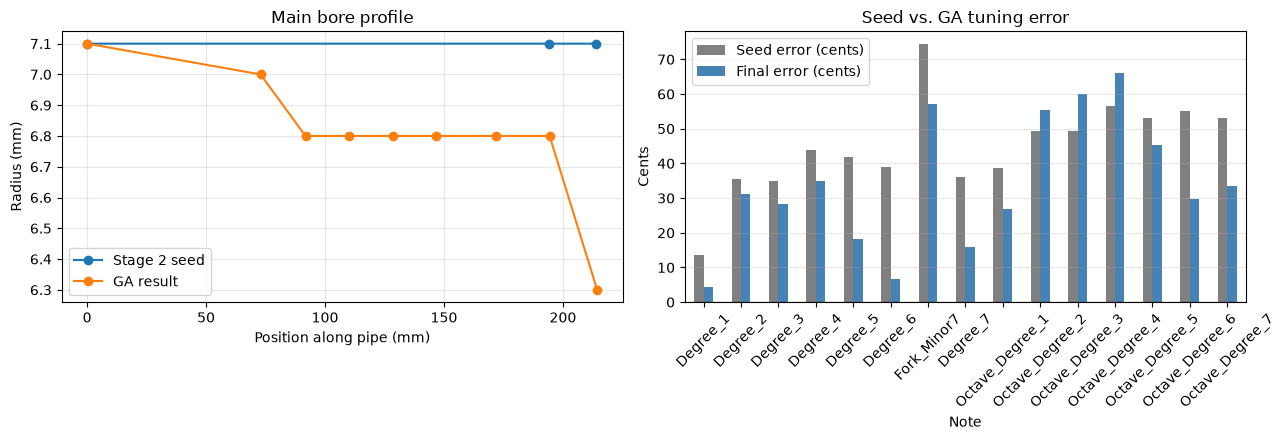

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

for label, bore in (("Stage 2 seed", seed_bore), ("GA result", ga_result.bore)):
    positions_mm = [point[0] * 1000 for point in bore.segments]
    radii_mm = [point[1] * 1000 for point in bore.segments]
    axes[0].plot(positions_mm, radii_mm, marker="o", label=label)
axes[0].set(title="Main bore profile", xlabel="Position along pipe (mm)", ylabel="Radius (mm)")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

tuning_table.plot.bar(ax=axes[1], color=["gray", "steelblue"], rot=45)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set(title="Seed vs. GA tuning error", ylabel="Cents", xlabel="Note")
axes[1].tick_params(axis="x", rotation=45)
axes[1].grid(True, axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

## 5. Finalize or export the design

Pass the winning geometry/layout into Stage 3 to produce the final design object. When the pipeline receives its own GA result layout, it retains the GA-selected bevel. The dictionary can be serialized as JSON or passed to the project's downstream reporting/export workflow.

In [ ]:
final_design = pipeline.run_stage_3_undercut_optimization(
    ga_result.bore,
    ga_result.layout,
)
design_payload = final_design.to_dict()
print(f"Final key: {final_design.key_name}")
print(f"Temperament: {final_design.temperament_name}")
print("Selected per-hole bevels (deg):", [hole.bevel_deg for hole in final_design.holes.holes])
print(f"Bore segment count: {len(final_design.bore.segments)}")
print(f"Tonehole count: {len(final_design.holes.holes)}")

# Optional JSON export (uncomment to write into the repository data directory):
# output_path = Path("data/genetic_whistle_design.json")
# output_path.write_text(json.dumps(design_payload, indent=2), encoding="utf-8")
# print(f"Wrote {output_path}")